<a href="https://colab.research.google.com/github/ituvtu/aerial-vehicle-detector/blob/main/notebooks/03_train_pretrained_backbone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 3: Train YOLO26-Pico-P2 with COCO Pretrained Stem Transfer (`03_train_pretrained_backbone.ipynb`)

### Experiment 3: `exp3_pretrained` (Model Registry `m003`)

This notebook trains our custom <500k parameter detector initialized with **pretrained COCO stem/backbone weights** transferred from `yolo26n.pt` into layers 0..4 (stem convolutions and C3k2 feature extractors).

Key constraints:
- **Rule 1 (Data Split Isolation)**: Video-level isolation strictly maintained. `eval` and `eval_B` are isolated in `test`.
- **Rule 4 (Optical Distance Stratification)**: Evaluation across `0–200 m` (near) and `200–400 m` (far).
- **Rule 5 (Parameter Constraint)**: < 500,000 parameters strictly enforced.

In [1]:
# === CELL 1: GPU & REPOSITORY SETUP ===
import os
import sys
from pathlib import Path
import torch

GITHUB_REPO_URL = "https://github.com/ituvtu/aerial-vehicle-detector.git"
REPO_DIR = Path("/content/aerial-vehicle-detector")

if not REPO_DIR.exists():
    !git clone {GITHUB_REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull --ff-only origin main

%cd {REPO_DIR}

!pip install -q "ultralytics>=8.4.0" "git+https://github.com/ultralytics/CLIP.git" "pandas" "pyyaml" "matplotlib"

print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    !nvidia-smi

Cloning into '/content/aerial-vehicle-detector'...
remote: Enumerating objects: 517, done.
remote: Counting objects: 100% (517/517), done.
remote: Compressing objects: 100% (453/453), done.
remote: Total 517 (delta 89), reused 478 (delta 52), pack-reused 0 (from 0)
Receiving objects: 100% (517/517), 16.85 MiB | 42.08 MiB/s, done.
Resolving deltas: 100% (89/89), done.
/content/aerial-vehicle-detector
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch: 2.11.0+cu130 | CUDA available: True
GPU Device: NVIDIA A100-SXM4-40GB
Wed Nov  4 23:24:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volati

In [2]:
# === CELL 2: DATASET SYNCHRONIZATION ===
import yaml
from src.manifest_manager import ensure_images_available, ensure_raw_eval_video_available, sync_manifest_splits

with open("configs/project_config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

ensure_images_available(
    manifest_path=cfg["paths"]["manifest_path"],
    images_dir=cfg["paths"]["images_dir"],
    bundle_zip_path=cfg["paths"]["images_bundle_zip"],
    bundle_url=cfg.get("remote_data", {}).get("images_bundle_url"),
)
split_counts = sync_manifest_splits()
print("Frames unpacked. Dataset split distribution:", split_counts)

# Ensure raw 30 FPS evaluation video is downloaded for full-fidelity evaluation demo
raw_eval_video = ensure_raw_eval_video_available("32179597")
print(f"Raw evaluation video ready: {raw_eval_video} ({raw_eval_video.stat().st_size / 1e6:.1f} MB)")

[Auto-Fetch] Downloading https://huggingface.co/datasets/ituvtu/aerial-vehicle-detector-data/resolve/main/images_bundle.zip -> data/images_bundle.zip ...
[Auto-Fetch] Extracting 'data/images_bundle.zip' into 'data/images' ...
Frames unpacked. Dataset split distribution: {'train': 73, 'val': 18, 'test': 64}
[Raw Video] Downloading '32179597.mp4' from https://huggingface.co/datasets/ituvtu/aerial-vehicle-detector-data/resolve/main/32179597.mp4 ...
[Auto-Fetch] Downloading https://huggingface.co/datasets/ituvtu/aerial-vehicle-detector-data/resolve/main/32179597.mp4 -> data/raw_videos/32179597.mp4 ...
[Raw Video] Successfully fetched '32179597.mp4' (58.1 MB)
Raw evaluation video ready: data/raw_videos/32179597.mp4 (58.1 MB)


In [3]:
# === CELL 3: ARCHITECTURE & PRETRAINED STEM TRANSFER VERIFICATION ===
from ultralytics import YOLO
from src.metrics import inspect_and_verify_architecture
from src.model_registry import create_pretrained_pico_checkpoint

# Verify architecture parameter limits (<500k params, Rule 5)
arch_report = inspect_and_verify_architecture(
    yaml_path="configs/yolo26_pico_p2.yaml",
    pretrained_weights="yolo26n.pt",
    output_report_path="results/model_architecture_report.json",
    max_params=500_000,
)

print(f"\nArchitecture Verified: {arch_report['unfused_params']:,} unfused / {arch_report['fused_params']:,} fused params")

# Persist pretrained stem into a real .pt checkpoint (also updates the architecture report)
transfer_info = create_pretrained_pico_checkpoint(
    yaml_path="configs/yolo26_pico_p2.yaml",
    backbone_source="yolo26n.pt",
    output_path="weights/pico_p2_pretrained_init.pt",
)
X, N = transfer_info["transferred_items"], transfer_info["total_items"]
assert X > 0, "Pretrained transfer failed: 0 tensors transferred"
print(f"Transferred {X}/{N} tensors into pico_p2_pretrained_init.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ no model scale passed. Assuming scale='n'.
layer                                    name                type  gradient  parameters               shape        mu     sigma
    0                     model.0.conv.weight              Conv2d      True         432       [16, 3, 3, 3]   0.00237      0.11        float32
    1                       model.0.bn.weight         BatchNorm2d      True          16                [16]         1         0        float32
    1                         model.0.bn.bias         BatchNorm2d      True          16                [16]         0         0        float32
    2                             model.0.act                SiLU     False           0          

/usr/local/lib/python3.13/dist-packages/ultralytics/utils/torch_utils.py:575: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  f"{i:>5g}{f'{mn}.{pn}':>40}{mt:>20}{p.requires_grad!r:>10}{p.numel():>12g}{list(p.shape)!s:>20}{p.mean():>10.3g}{p.std():>10.3g}{str(p.dtype).replace('torch.', ''):>15}"


YOLO26_pico_p2 summary: 236 layers, 478,590 parameters, 478,590 gradients, 5.3 GFLOPs
Transferred 58/648 items from pretrained weights
[Architecture Inspection] Saved report to results/model_architecture_report.json

Architecture Verified: 478,590 unfused / 427,567 fused params
WARNING ⚠️ no model scale passed. Assuming scale='n'.
Transferred 46/66 tensors into pico_p2_pretrained_init.pt
Transferred 46/66 tensors into pico_p2_pretrained_init.pt


In [4]:
# === CELL 4: TRAINING (exp3_pretrained) ===
# Trains YOLO26-Pico-P2 with transferred stem weights on 73 train frames
!python scripts/04_train.py --mode exp3_pretrained --pretrained-stem --epochs 150 --batch 8 --imgsz 1024

WARNING ⚠️ no model scale passed. Assuming scale='n'.
layer                                    name                type  gradient  parameters               shape        mu     sigma
    0                     model.0.conv.weight              Conv2d      True         432       [16, 3, 3, 3]  -0.00133     0.112        float32
    1                       model.0.bn.weight         BatchNorm2d      True          16                [16]         1         0        float32
    1                         model.0.bn.bias         BatchNorm2d      True          16                [16]         0         0        float32
    2                             model.0.act                SiLU     False           0                  []         -         -              -
    3                     model.1.conv.weight              Conv2d      True        4608      [32, 16, 3, 3]  0.000908    0.0483        float32
    4                       model.1.bn.weight         BatchNorm2d      True          32                


Active Champion: m001

ID     Exp Name               Macro-F1   mAP@0.5    Score    Conf   Params(F)  Champion
--------------------------------------------------------------------------------------
m001   exp3_pretrained        0.7500     0.7432     0.7466   0.25   427,567    ★ YES



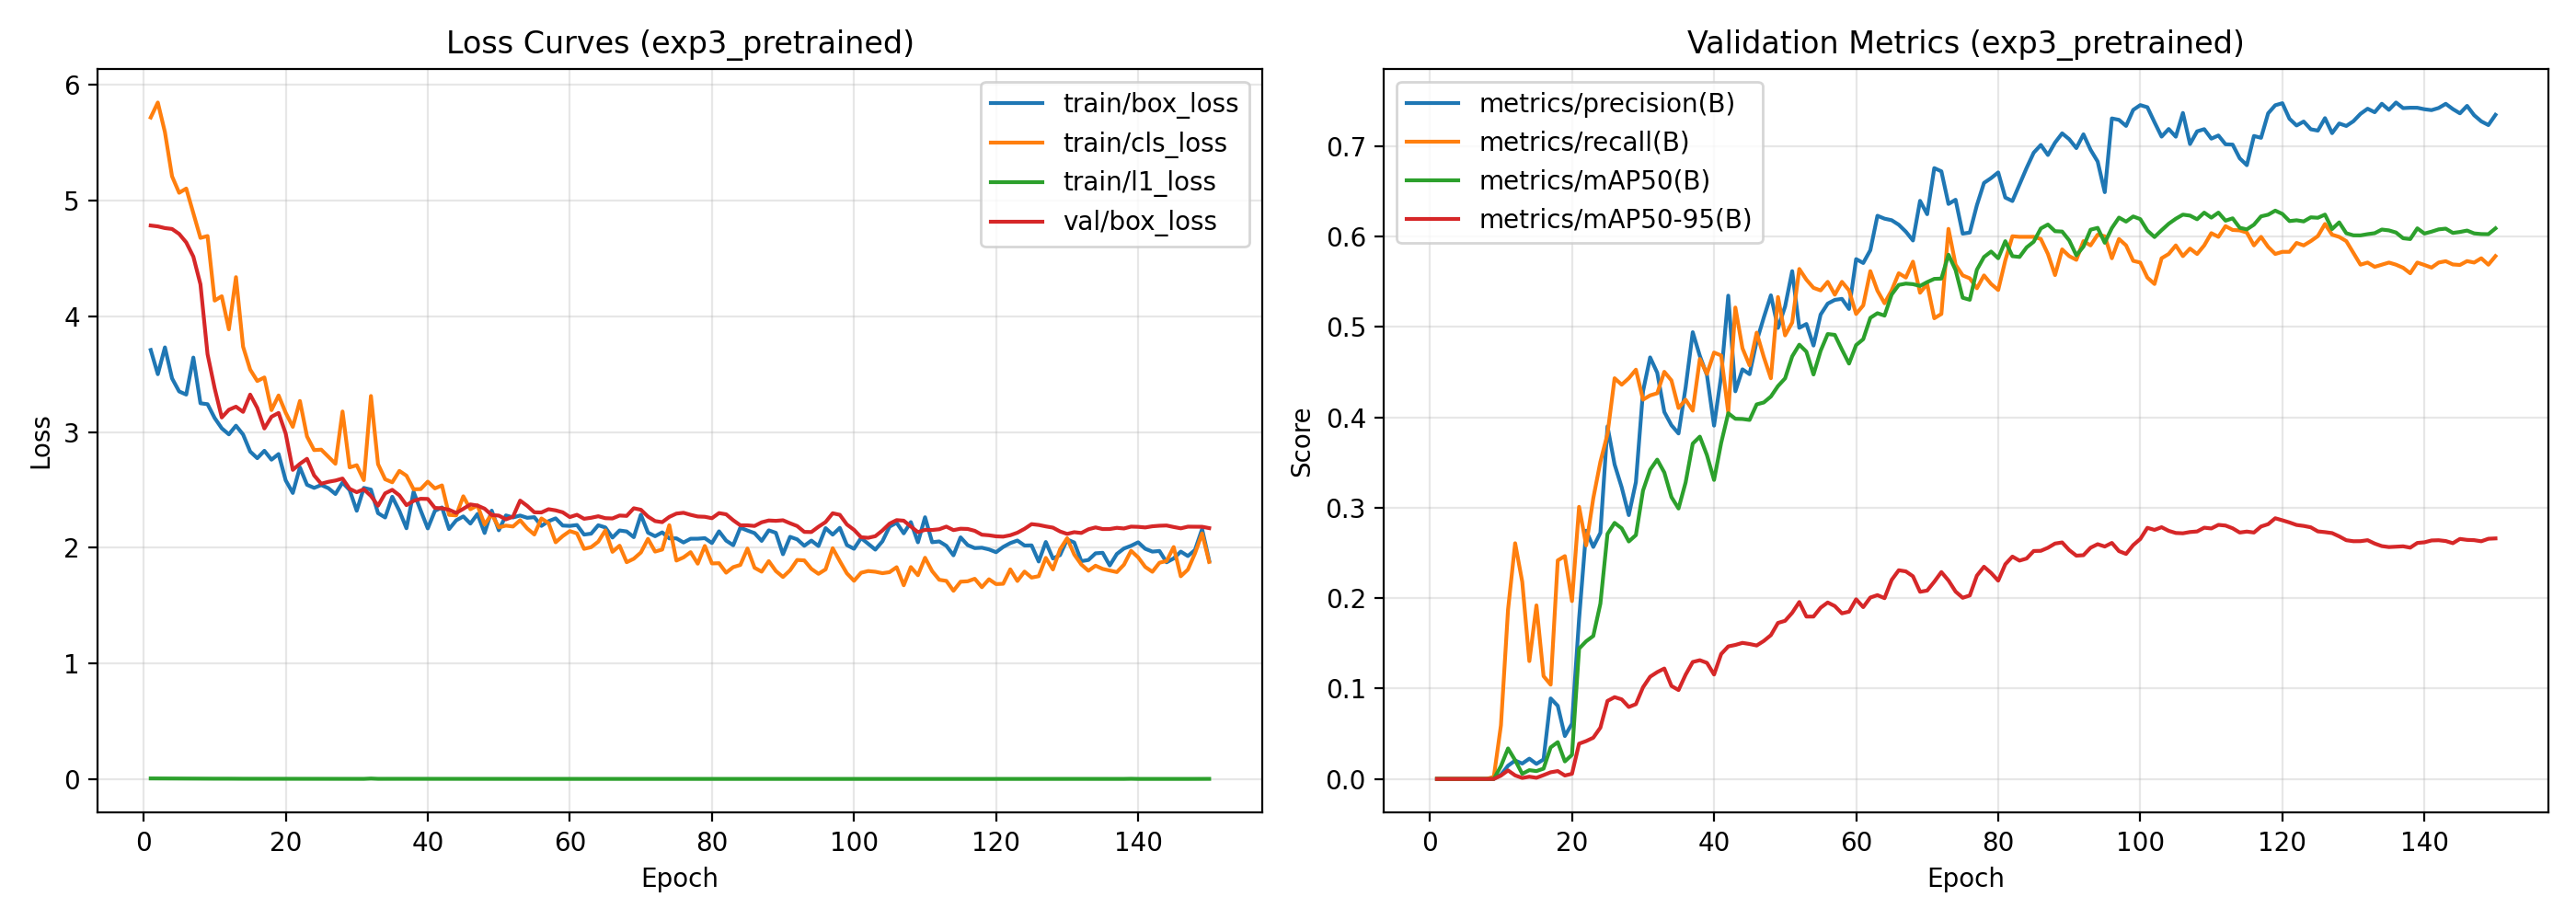

In [5]:
# === CELL 5: TRAINING TELEMETRY & VALIDATION CALIBRATION ===
from IPython.display import Image, display
from pathlib import Path

# Show registered models in ledger
!python scripts/04_train.py --list-models

curves_p = Path("results/training_curves_exp3_pretrained.png")
if curves_p.exists():
    display(Image(filename=str(curves_p)))

In [6]:
# === CELL 6: INDEPENDENT TEST EVALUATION (m003) ===
# Decoupled evaluation on held-out test split (eval + eval_B)
!python scripts/05_evaluate.py --weights weights/exp3_pretrained_best.pt --calibration weights/calibration_val_exp3_pretrained.json

from IPython.display import Markdown, display
from pathlib import Path

eval_summary_p = Path("results/eval_summary_table.md")
if eval_summary_p.exists():
    display(Markdown(eval_summary_p.read_text(encoding="utf-8")))

[Evaluation] Using calibrated validation threshold: tau* = 0.25 (from calibration_val_exp3_pretrained.json)
[Evaluation] Testing on held-out test clips: ['eval', 'eval_B'] (64 total frames)
[Evaluation] Running inference on 64 held-out test frames (imgsz=1024, rect=True) ...
[Evaluation] Saved metrics and summary tables to /content/aerial-vehicle-detector/results and /content/aerial-vehicle-detector/results/evaluations/custom_weights_20261104T232938Z
[Evaluation] Saved 8 sample crops to /content/aerial-vehicle-detector/results/eval_samples
[Evaluation] Rendered 1-FPS test comparison video: /content/aerial-vehicle-detector/results/eval_gt_vs_pred_1fps.mp4

[Evaluation] Rendering Full 30.0 FPS Demo Video on 32179597.mp4 ...
[Evaluation] Successfully rendered 918 frames at 30.0 FPS to: /content/aerial-vehicle-detector/results/eval_demo_32179597_full_fps.mp4


# Evaluation Results: YOLO26-Pico-P2 on Held-Out Test Split (Rule 1 & Rule 4)

**Model ID**: `custom_weights` | **Weights SHA**: `3af3f707` | **Parameters**: 427,567 fused (<500k limit)
**Latency**: 19.3 ms mean (51.8 FPS), P95 = 19.3 ms (<33ms real-time: `True`)
**Confidence Threshold**: $\tau^* = 0.25$ (calibrated on val split)

### Test Split Performance Across Optical Distance Bands

| Distance Band | Target Distance | GT Vehicles | True Positives (TP) | False Positives (FP) | False Negatives (FN) | Detection Rate (Recall) | Precision | F1 Score | mAP@0.5 | TTFD (s) | False Alarms / min |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0-200m** | 0–200 m (near) | 441 | 108 | 220 | 333 | 24.5% | 32.9% | 28.1% | 0.2457 | 1.02s | 206.25 |
| **200-400m** | 200–400 m (far) | 352 | 132 | 120 | 220 | 37.5% | 52.4% | 43.7% | 0.3596 | 0.02s | 112.50 |
| **overall_0_400m** | 0–400 m (target task) | 793 | 240 | 340 | 553 | 30.3% | 41.4% | 35.0% | 0.2688 | 1.02s | 318.75 |
| **>400m** | >400 m (ambient background) | 46 | 3 | 25 | 43 | 6.5% | 10.7% | 8.1% | 0.0301 | 17.02s | 23.44 |
| **overall_all** | All Distances (0–∞ m) | 839 | 243 | 365 | 596 | 29.0% | 40.0% | 33.6% | 0.2436 | 1.02s | 342.19 |

### Per-Clip Performance Breakdown (Rule 1 & Rule 4)

| Clip Role | Video ID | Frames | 0–200m Recall | 200–400m Recall | 0–400m F1 | mAP@0.5 | TTFD Delay |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **eval** | `32179597` | 31 | 32.9% | 100.0% | 15.5% | 0.0908 | 2.02s |
| **eval_B** | `13763017` | 33 | 22.5% | 37.5% | 41.9% | 0.4454 | 0.02s |


In [8]:
# === CELL 7: PACKAGE & DOWNLOAD DELIVERABLES BUNDLE ===
import datetime
import zipfile
from pathlib import Path

timestamp = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
bundle_zip = Path(f"colab_results_bundle_m003_{timestamp}.zip")

include_dirs = [Path("weights"), Path("results"), Path("assets"), Path("data/registry")]

with zipfile.ZipFile(bundle_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder in include_dirs:
        if folder.exists():
            for item in folder.rglob("*"):
                if item.is_file() and not item.name.endswith(".mp4") and item.stat().st_size < 50_000_000:
                    zf.write(item, arcname=item.as_posix())

print(f"Packaged deliverables bundle: {bundle_zip} ({bundle_zip.stat().st_size / 1e6:.2f} MB)")

try:
    from google.colab import files
    files.download(str(bundle_zip))
    print("Download triggered in browser.")
except (ImportError, Exception) as exc:
    print(f"Note: Running locally or download skipped: {exc}. Bundle saved at {bundle_zip}")

Packaged deliverables bundle: colab_results_bundle_m003_20261104T233147Z.zip (32.34 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered in browser.
